# Help Desk AI — Model Analysis & Evaluation

**Project:** Help Desk Ticket Classification & Anomaly Detection

This notebook is an **analysis/evaluation notebook** for the existing Python project. It does not retrain the model. It loads the project dataset and saved prediction outputs, evaluates classification performance, examines anomalies, and extracts operational insights.

### Models covered
- **BiLSTM multi-task classifier:** predicts ticket **Category** and **Priority**.
- **TF-IDF autoencoder anomaly detector:** identifies unusual ticket records.

> The existing Streamlit dashboard is intentionally not recreated here; this notebook focuses on model evaluation and deeper analysis.

## 1. Imports and configuration

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
)

from IPython.display import display

# Works when this notebook is placed in the project root.
# If you move the notebook elsewhere, update PROJECT_ROOT.
PROJECT_ROOT = Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "tickets.csv"
PRED_PATH = PROJECT_ROOT / "outputs" / "predictions.csv"
METRICS_PATH = PROJECT_ROOT / "outputs" / "metrics.json"

print("Project root:", PROJECT_ROOT)
print("Data exists:", DATA_PATH.exists())
print("Predictions exist:", PRED_PATH.exists())
print("Metrics exist:", METRICS_PATH.exists())

ModuleNotFoundError: No module named 'matplotlib'

## 2. Load the dataset and saved predictions

In [ ]:
import pandas as pd
import json

tickets = pd.read_csv("../data/tickets.csv")
predictions = pd.read_csv("../outputs/predictions.csv")

with open("../outputs/metrics.json", "r", encoding="utf-8") as f:
    metrics = json.load(f)

print("Tickets:", tickets.shape)
print("Predictions:", predictions.shape)
print("Metrics loaded successfully.")

Tickets: (5171, 11)
Predictions: (5171, 15)
Metrics loaded successfully.


## 3. Dataset overview

In [ ]:
display(tickets.head())
print("\nData types:")
display(tickets.dtypes.to_frame("dtype"))

print("\nMissing values:")
display(tickets.isna().sum().to_frame("missing_count"))

print("\nDuplicate ticket IDs:", tickets["ticket_id"].duplicated().sum())

,ticket_id,created_at,department,description,issue,category,priority,resolution_hours,resolution_action,true_outlier,split
0,INC100000,2025-03-03 16:01:00,HR,"hello, cannot stay connected to the vpn whenev...",VPN drops,Network,Medium,4.2,Restarted service,0,train
1,INC100001,2025-09-07 07:00:00,Engineering,excel keeps crashing third time this week,App crash,Software,High,38.8,Renewed licence,0,train
2,INC100002,2025-06-02 20:29:00,Engineering,since this morning emails bouncing back need t...,Spam,Email,High,7.1,Cleared mailbox,0,train
3,INC100003,2025-06-19 08:35:00,Marketing,"again today, no internet on my desk tried rest...",No internet,Network,High,9.9,Reconfigured router/VPN,0,train
4,INC100004,2025-02-12 02:09:00,Engineering,"hello, phone with work emali stolen low impatc...",Lost device,Security,Critical,18.7,Forced credential reset,0,train



Data types:


,dtype
ticket_id,str
created_at,str
department,str
description,str
issue,str
category,str
priority,str
resolution_hours,float64
resolution_action,str
true_outlier,int64



Missing values:


,missing_count
ticket_id,0
created_at,0
department,0
description,0
issue,0
category,0
priority,0
resolution_hours,0
resolution_action,0
true_outlier,0



Duplicate ticket IDs: 0


## 4. Dataset split

,ticket_count
split,
train,3619
val,775
test,777


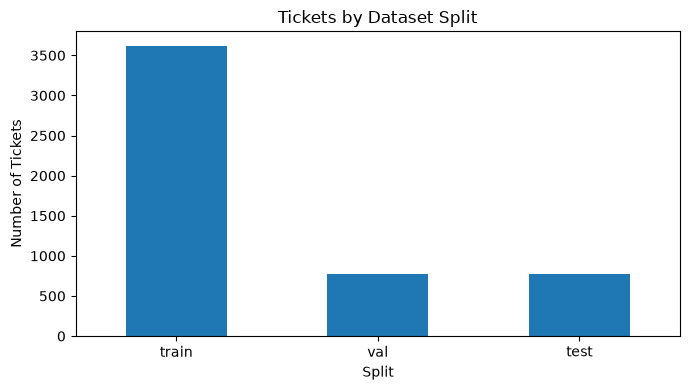

In [ ]:
split_counts = tickets["split"].value_counts().reindex(["train", "val", "test"]).fillna(0).astype(int)
display(split_counts.to_frame("ticket_count"))

plt.figure(figsize=(7, 4))
split_counts.plot(kind="bar")
plt.title("Tickets by Dataset Split")
plt.xlabel("Split")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Category distribution

,ticket_count
category,
Software,948
Network,918
Email,849
Access/Account,845
Security,842
Hardware,769


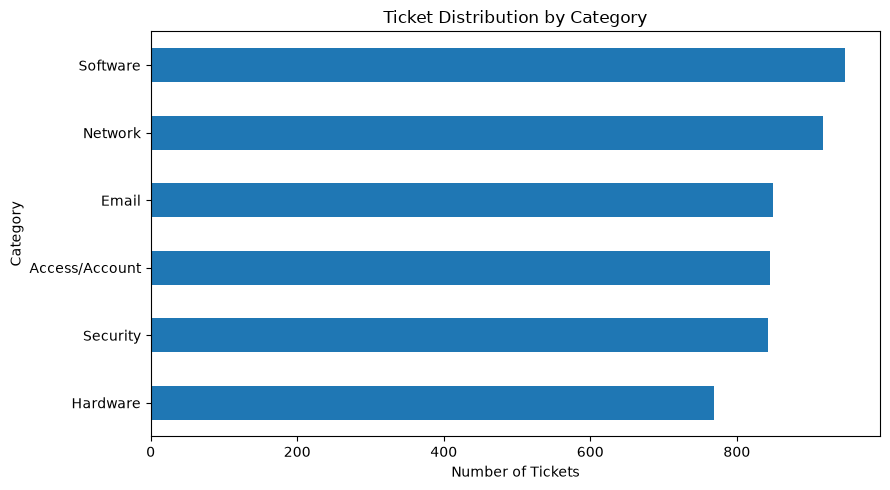

In [ ]:
category_counts = tickets["category"].value_counts()
display(category_counts.to_frame("ticket_count"))

plt.figure(figsize=(9, 5))
category_counts.sort_values().plot(kind="barh")
plt.title("Ticket Distribution by Category")
plt.xlabel("Number of Tickets")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

## 6. Priority distribution

,ticket_count
priority,
Low,1267
Medium,1418
High,1559
Critical,927


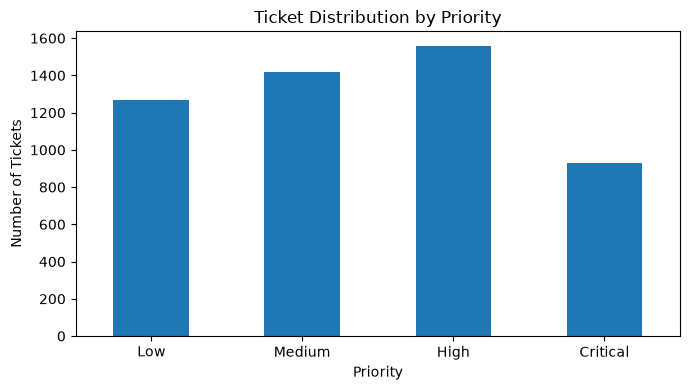

In [ ]:
priority_order = ["Low", "Medium", "High", "Critical"]
priority_counts = tickets["priority"].value_counts().reindex(priority_order).fillna(0).astype(int)
display(priority_counts.to_frame("ticket_count"))

plt.figure(figsize=(7, 4))
priority_counts.plot(kind="bar")
plt.title("Ticket Distribution by Priority")
plt.xlabel("Priority")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Merge predictions with the original dataset

In [ ]:
# The saved prediction file already contains the original fields plus prediction outputs.
# Use ticket_id to verify alignment and avoid relying on row order.
merged = tickets.merge(
    predictions[["ticket_id", "pred_category", "pred_priority", "anomaly_score", "is_anomaly"]],
    on="ticket_id",
    how="left",
    validate="one_to_one",
)

print("Merged shape:", merged.shape)
print("Missing prediction rows:", merged["pred_category"].isna().sum())
display(merged.head())

Merged shape: (5171, 15)
Missing prediction rows: 0


,ticket_id,created_at,department,description,issue,category,priority,resolution_hours,resolution_action,true_outlier,split,pred_category,pred_priority,anomaly_score,is_anomaly
0,INC100000,2025-03-03 16:01:00,HR,"hello, cannot stay connected to the vpn whenev...",VPN drops,Network,Medium,4.2,Restarted service,0,train,Network,Medium,0.001414,0
1,INC100001,2025-09-07 07:00:00,Engineering,excel keeps crashing third time this week,App crash,Software,High,38.8,Renewed licence,0,train,Software,Medium,0.001993,0
2,INC100002,2025-06-02 20:29:00,Engineering,since this morning emails bouncing back need t...,Spam,Email,High,7.1,Cleared mailbox,0,train,Email,High,0.001440,0
3,INC100003,2025-06-19 08:35:00,Marketing,"again today, no internet on my desk tried rest...",No internet,Network,High,9.9,Reconfigured router/VPN,0,train,Network,Medium,0.002075,0
4,INC100004,2025-02-12 02:09:00,Engineering,"hello, phone with work emali stolen low impatc...",Lost device,Security,Critical,18.7,Forced credential reset,0,train,Security,High,0.002261,0


## 8. Load and display saved model metrics

In [2]:
metrics_table = pd.DataFrame({
    "Metric": [
        "Category Accuracy", "Category Macro-F1",
        "Priority Accuracy", "Priority Macro-F1",
        "Anomaly Flagged (%)", "Anomaly Recall", "Anomaly Precision"
    ],
    "Validation": [
        metrics["val"]["category_acc"], metrics["val"]["category_f1"],
        metrics["val"]["priority_acc"], metrics["val"]["priority_f1"],
        np.nan, np.nan, np.nan
    ],
    "Test": [
        metrics["test"]["category_acc"], metrics["test"]["category_f1"],
        metrics["test"]["priority_acc"], metrics["test"]["priority_f1"],
        metrics["anomaly_test"]["flagged_pct"],
        metrics["anomaly_test"]["recall_on_synthetic_outliers"],
        metrics["anomaly_test"]["precision"]
    ]
})

display(metrics_table.style.format({"Validation": "{:.3f}", "Test": "{:.3f}"}))

NameError: name 'metrics' is not defined

## 9. Category classification — test-set evaluation

In [20]:
test_df = merged[merged["split"] == "test"].copy()

y_true_cat = test_df["category"]
y_pred_cat = test_df["pred_category"]

cat_acc = accuracy_score(y_true_cat, y_pred_cat)
cat_f1 = f1_score(y_true_cat, y_pred_cat, average="macro")

print(f"Category Test Accuracy : {cat_acc:.3f}")
print(f"Category Test Macro-F1 : {cat_f1:.3f}")
print("\nClassification Report:")
print(classification_report(y_true_cat, y_pred_cat, zero_division=0))

Category Test Accuracy : 0.879
Category Test Macro-F1 : 0.878

Classification Report:
                precision    recall  f1-score   support

Access/Account       0.91      0.85      0.88       116
         Email       0.88      0.90      0.89       131
      Hardware       0.82      0.94      0.88       140
       Network       0.87      0.86      0.87       128
      Security       0.92      0.93      0.93       134
      Software       0.89      0.77      0.83       128

      accuracy                           0.88       777
     macro avg       0.88      0.88      0.88       777
  weighted avg       0.88      0.88      0.88       777



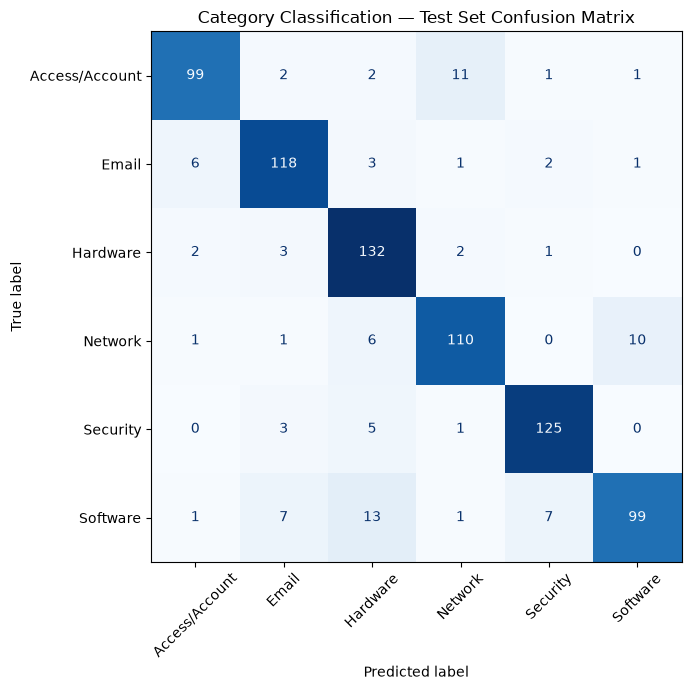

In [21]:
labels_cat = sorted(test_df["category"].dropna().unique())
cm_cat = confusion_matrix(y_true_cat, y_pred_cat, labels=labels_cat)

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(confusion_matrix=cm_cat, display_labels=labels_cat).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False
)
ax.set_title("Category Classification — Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

## 10. Priority classification — test-set evaluation

In [22]:
y_true_pri = test_df["priority"]
y_pred_pri = test_df["pred_priority"]

pri_acc = accuracy_score(y_true_pri, y_pred_pri)
pri_f1 = f1_score(y_true_pri, y_pred_pri, average="macro")

print(f"Priority Test Accuracy : {pri_acc:.3f}")
print(f"Priority Test Macro-F1 : {pri_f1:.3f}")
print("\nClassification Report:")
print(classification_report(y_true_pri, y_pred_pri, zero_division=0))

Priority Test Accuracy : 0.665
Priority Test Macro-F1 : 0.669

Classification Report:
              precision    recall  f1-score   support

    Critical       0.89      0.64      0.75       133
        High       0.73      0.66      0.69       244
         Low       0.77      0.48      0.59       178
      Medium       0.53      0.83      0.65       222

    accuracy                           0.67       777
   macro avg       0.73      0.65      0.67       777
weighted avg       0.71      0.67      0.67       777



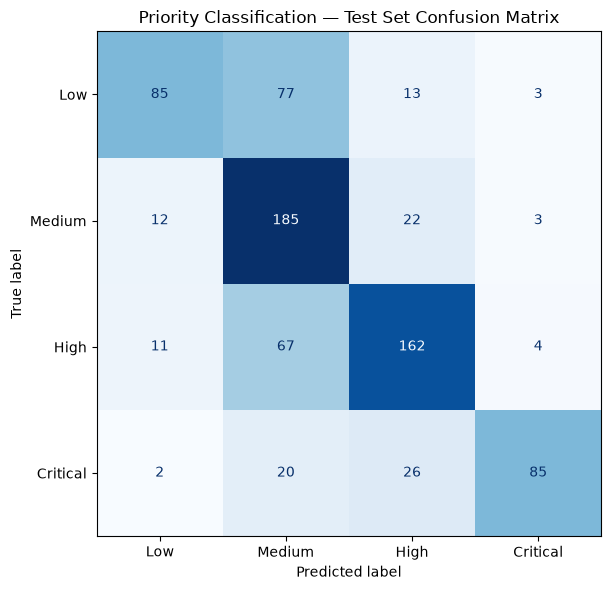

In [23]:
labels_pri = [x for x in priority_order if x in test_df["priority"].unique()]
cm_pri = confusion_matrix(y_true_pri, y_pred_pri, labels=labels_pri)

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix=cm_pri, display_labels=labels_pri).plot(
    ax=ax, cmap="Blues", colorbar=False
)
ax.set_title("Priority Classification — Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

## 11. Category vs Priority performance

,Task,Accuracy,Macro-F1
0,Category,0.879,0.878
1,Priority,0.665,0.669


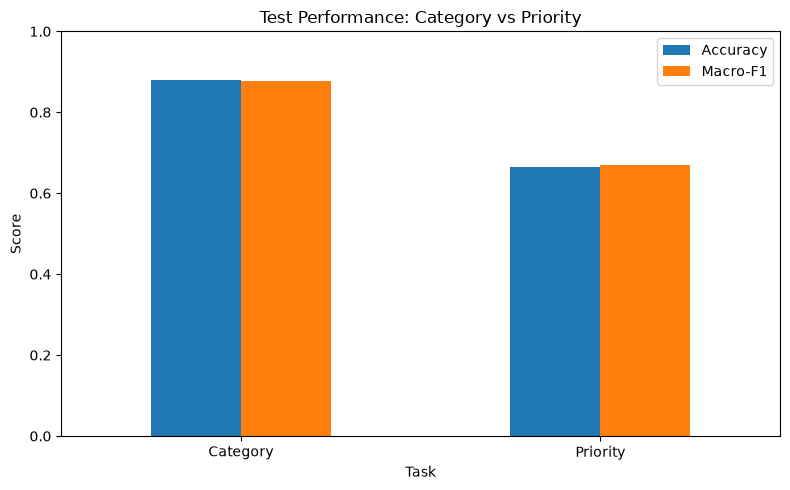

In [24]:
comparison = pd.DataFrame({
    "Task": ["Category", "Priority"],
    "Accuracy": [cat_acc, pri_acc],
    "Macro-F1": [cat_f1, pri_f1]
})
display(comparison.style.format({"Accuracy": "{:.3f}", "Macro-F1": "{:.3f}"}))

ax = comparison.set_index("Task")[["Accuracy", "Macro-F1"]].plot(kind="bar", figsize=(8, 5))
ax.set_title("Test Performance: Category vs Priority")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 12. Error analysis

In [25]:
category_errors = test_df[test_df["category"] != test_df["pred_category"]].copy()
priority_errors = test_df[test_df["priority"] != test_df["pred_priority"]].copy()

print("Category errors:", len(category_errors))
print("Priority errors:", len(priority_errors))

print("\nMost common category confusions:")
cat_confusions = (
    category_errors.groupby(["category", "pred_category"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)
display(cat_confusions.head(10))

print("Most common priority confusions:")
pri_confusions = (
    priority_errors.groupby(["priority", "pred_priority"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)
display(pri_confusions.head(10))

Category errors: 94
Priority errors: 260

Most common category confusions:


,category,pred_category,count
23,Software,Hardware,13
2,Access/Account,Network,11
17,Network,Software,10
22,Software,Email,7
25,Software,Security,7
16,Network,Hardware,6
5,Email,Access/Account,6
19,Security,Hardware,5
6,Email,Hardware,3
11,Hardware,Email,3


Most common priority confusions:


,priority,pred_priority,count
8,Low,Medium,77
5,High,Medium,67
0,Critical,High,26
10,Medium,High,22
2,Critical,Medium,20
7,Low,High,13
11,Medium,Low,12
4,High,Low,11
3,High,Critical,4
6,Low,Critical,3


## 13. Resolution-time analysis

,count,mean,median,min,max
priority,,,,,
Low,1267,9.04,5.40,0.4,84.4
Medium,1418,15.97,10.15,0.5,298.9
High,1559,23.80,16.20,0.7,211.0
Critical,927,13.74,10.10,0.8,102.0


<Figure size 800x500 with 0 Axes>

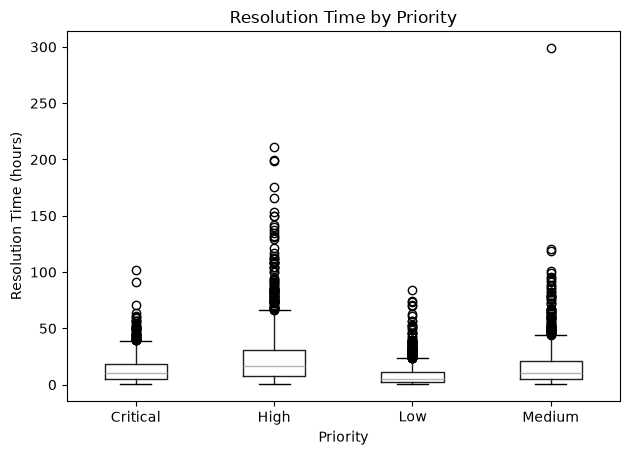

In [26]:
resolution_summary = (
    tickets.groupby("priority")["resolution_hours"]
    .agg(["count", "mean", "median", "min", "max"])
    .reindex(priority_order)
)
display(resolution_summary.round(2))

plt.figure(figsize=(8, 5))
tickets.boxplot(column="resolution_hours", by="priority", grid=False)
plt.title("Resolution Time by Priority")
plt.suptitle("")
plt.xlabel("Priority")
plt.ylabel("Resolution Time (hours)")
plt.tight_layout()
plt.show()

## 14. Resolution action analysis

,ticket_count
resolution_action,
Isolated device,327
Swapped device,319
Escalated to network team,317
Granted permission,303
Reinstalled app,296
Blocked sender,295
Re-synced profile,291
Adjusted spam rules,283
Renewed licence,282


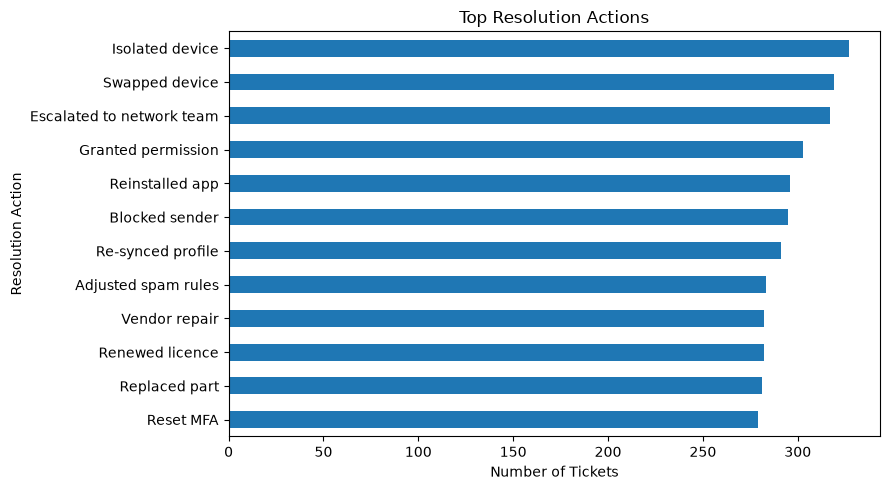

In [27]:
action_counts = tickets["resolution_action"].value_counts().head(12)
display(action_counts.to_frame("ticket_count"))

plt.figure(figsize=(9, 5))
action_counts.sort_values().plot(kind="barh")
plt.title("Top Resolution Actions")
plt.xlabel("Number of Tickets")
plt.ylabel("Resolution Action")
plt.tight_layout()
plt.show()

## 15. Anomaly detection analysis

Tickets flagged as anomalies: 197 / 5,171
Overall anomaly flag rate: 3.81%


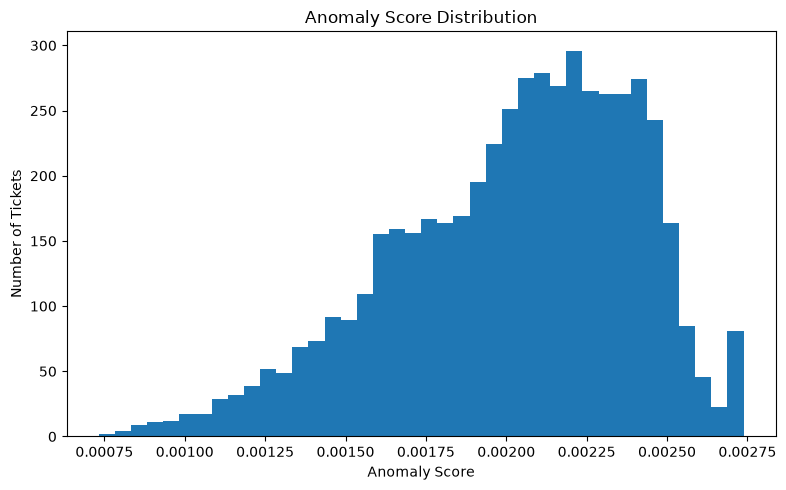

In [28]:
anomaly_rate = merged["is_anomaly"].mean() * 100
print(f"Tickets flagged as anomalies: {merged['is_anomaly'].sum():,} / {len(merged):,}")
print(f"Overall anomaly flag rate: {anomaly_rate:.2f}%")

plt.figure(figsize=(8, 5))
plt.hist(merged["anomaly_score"].dropna(), bins=40)
plt.title("Anomaly Score Distribution")
plt.xlabel("Anomaly Score")
plt.ylabel("Number of Tickets")
plt.tight_layout()
plt.show()

## 16. Anomaly detector vs synthetic outlier labels

In [29]:
# The dataset contains a synthetic ground-truth outlier label named true_outlier.
# Evaluate the detector on the test split only.
an_test = test_df.dropna(subset=["anomaly_score", "true_outlier", "is_anomaly"]).copy()

y_out_true = an_test["true_outlier"].astype(int)
y_out_pred = an_test["is_anomaly"].astype(int)

print(f"Outlier precision: {precision_score(y_out_true, y_out_pred, zero_division=0):.3f}")
print(f"Outlier recall   : {recall_score(y_out_true, y_out_pred, zero_division=0):.3f}")
print(f"Outlier F1       : {f1_score(y_out_true, y_out_pred, zero_division=0):.3f}")
print("\nConfusion matrix:")
print(confusion_matrix(y_out_true, y_out_pred))

Outlier precision: 0.520
Outlier recall   : 0.619
Outlier F1       : 0.565

Confusion matrix:
[[744  12]
 [  8  13]]


## 17. Top unusual tickets

In [30]:
top_anomalies = (
    merged.sort_values("anomaly_score", ascending=False)
    [["ticket_id", "department", "issue", "category", "priority",
      "resolution_hours", "anomaly_score", "is_anomaly", "description"]]
    .head(20)
)

display(top_anomalies)

,ticket_id,department,issue,category,priority,resolution_hours,anomaly_score,is_anomaly,description
1107,INC101107,Finance,Miscellaneous,Software,Critical,6.5,0.002738,1,plant travel booking cinema test
4335,INC104335,Sales,Miscellaneous,Hardware,High,29.0,0.002736,1,banana room fridge lunch invoice
3938,INC103938,Engineering,Miscellaneous,Access/Account,High,1.6,0.002736,1,room recipe budget chair yoga invoice random l...
5016,INC105016,Support,Miscellaneous,Email,Low,3.8,0.002728,1,ignore booking decoration room coffee
4925,INC104925,Sales,Miscellaneous,Hardware,Medium,65.8,0.002728,1,window budget plant banana permit recpie yoga
1697,INC101697,Sales,Miscellaneous,Hardware,Medium,30.1,0.002726,1,catering reimbursement travel microwave machin...
1283,INC101283,HR,Miscellaneous,Security,Medium,3.5,0.002725,1,permit travel parking catering party chair
523,INC100523,Marketing,Miscellaneous,Email,Low,7.2,0.002725,1,gym voucher booking reimbursement parking deco...
2824,INC102824,HR,Miscellaneous,Security,Medium,5.4,0.002724,1,ticket pizza parking travel
1454,INC101454,Support,Miscellaneous,Security,High,91.4,0.002724,1,banana desk macihne plant chair


## 18. Operational insights

In [31]:
# Generate concise data-driven observations for the project report.
high_critical_share = tickets["priority"].isin(["High", "Critical"]).mean() * 100
avg_resolution = tickets["resolution_hours"].mean()
median_resolution = tickets["resolution_hours"].median()
top_department = tickets["department"].value_counts().idxmax()
top_category = tickets["category"].value_counts().idxmax()

print(f"• Total tickets analysed: {len(tickets):,}")
print(f"• High/Critical priority share: {high_critical_share:.1f}%")
print(f"• Average resolution time: {avg_resolution:.1f} hours")
print(f"• Median resolution time: {median_resolution:.1f} hours")
print(f"• Most represented department: {top_department}")
print(f"• Most represented category: {top_category}")
print(f"• Overall anomaly flag rate: {anomaly_rate:.1f}%")

• Total tickets analysed: 5,171
• High/Critical priority share: 48.1%
• Average resolution time: 16.2 hours
• Median resolution time: 9.9 hours
• Most represented department: Engineering
• Most represented category: Software
• Overall anomaly flag rate: 3.8%


## 19. Final evaluation summary

In [32]:
print("HELP DESK AI — FINAL EVALUATION SUMMARY")
print("=" * 45)
print(f"Category accuracy : {cat_acc:.1%}")
print(f"Category Macro-F1 : {cat_f1:.3f}")
print(f"Priority accuracy : {pri_acc:.1%}")
print(f"Priority Macro-F1 : {pri_f1:.3f}")
print(f"Anomaly rate      : {anomaly_rate:.1f}%")
print(f"Anomaly precision : {precision_score(y_out_true, y_out_pred, zero_division=0):.3f}")
print(f"Anomaly recall    : {recall_score(y_out_true, y_out_pred, zero_division=0):.3f}")

print("\nInterpretation:")
print("- Category classification performs better than priority classification on the saved test results.")
print("- Priority prediction is a more difficult task in this dataset and should be discussed as a limitation.")
print("- The anomaly detector identifies a small subset of tickets as unusual; its precision and recall should be considered when interpreting flags.")
print("- The notebook evaluates the saved model outputs and does not retrain or modify the production/dashboard pipeline.")

HELP DESK AI — FINAL EVALUATION SUMMARY
Category accuracy : 87.9%
Category Macro-F1 : 0.878
Priority accuracy : 66.5%
Priority Macro-F1 : 0.669
Anomaly rate      : 3.8%
Anomaly precision : 0.520
Anomaly recall    : 0.619

Interpretation:
- Category classification performs better than priority classification on the saved test results.
- Priority prediction is a more difficult task in this dataset and should be discussed as a limitation.
- The anomaly detector identifies a small subset of tickets as unusual; its precision and recall should be considered when interpreting flags.
- The notebook evaluates the saved model outputs and does not retrain or modify the production/dashboard pipeline.
